# Milk category analysis on quick commerce

The platform publishes no sales data, but it does show live stock. Stock was logged every 30 minutes for one Bengaluru address (HSR Layout), and **each fall in stock between two snapshots is treated as estimated sales**. All sales figures are estimates at listed prices, not reported revenue.

| Step | Question |
|---|---|
| **0. Setup and data health** | Can the data be trusted? |
| **1. Market distribution** | Who sells what, and who earns the value? |
| **2. Pricing** | Where do price tiers and pack sizes sit? |
| **3. Sales** | How much sells, and when? |
| **4. Inventory** | When is stock refilled, and how long do stockouts last? |
| **5. Fill rates and availability** | How often is a product available, by day and hour? What might that cost? |
| **6. Brand substitution** | When a brand runs short, who gains? |
| **7. Product substitution** | When a product is out, which product gains? |
| **8. Top 10 substitutions** | Which of those results matter most? |

## Step 0. Setup and data health

### 0.1 Load the data
Raw snapshots are private. In Colab, you're asked to upload `stock_snapshots.csv.gz` and `snapshot_log.csv` if they aren't already there. Change `D0` and `D1` to analyse a different window.

In [1]:
import os, re
FILES = ["stock_snapshots.csv.gz", "snapshot_log.csv"]
DATA = next((d for d in ["./", "../data/", "data/"] if all(os.path.exists(d + f) for f in FILES)), None)
if DATA is None:
    from google.colab import files
    files.upload()
    DATA = "./"
ROOT = "../" if os.path.exists("../README.md") else "./"
for folder in ("charts", "results"):
    os.makedirs(ROOT + folder, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

D0, D1 = "2026-10-06", "2026-11-01"     # full days only: 5 Oct is partial
SEED, RESAMPLES = 7, 2000                # bootstrap settings for steps 6 and 7

INK, ACCENT, BLUE, GOLD, GREY = "#2B2A33", "#E8593C", "#7E86B8", "#EFA93F", "#C9C7C1"
PALETTE = ["#E8593C", "#7E86B8", "#EFA93F", "#B9A6E0", "#C94A24", "#A9CFE3", "#7FAE8A", "#E7C27D"]
plt.rcParams.update({"figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.titlecolor": INK, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ECEBE7", "axes.axisbelow": True})
pd.set_option("display.max_columns", None, "display.width", 200)

def rupee(v):
    s = str(int(round(v)))
    return "₹" + (re.sub(r"(\d+?)(?=(\d\d)+$)", r"\1,", s[:-3]) + "," + s[-3:] if len(s) > 3 else s)

def save(name):
    plt.tight_layout(); plt.savefig(f"{ROOT}charts/{name}.png", dpi=160); plt.show()

def scroll(df, height=420):
    """Show a long table in a scrolling box."""
    display(HTML(f'<div style="max-height:{height}px;overflow:auto">{df.to_html(index=False)}</div>'))

snap = pd.read_csv(DATA + FILES[0], dtype={"product_id": str, "store_id": str})
runs = pd.read_csv(DATA + FILES[1], dtype=str)
print(f"{len(snap):,} rows | {snap.snapshot_time.nunique():,} snapshots | {snap.product_id.nunique()} products | "
      f"{snap.brand.nunique()} brands | {snap.snapshot_time.min()} to {snap.snapshot_time.max()}")

81,071 rows | 1,297 snapshots | 105 products | 22 brands | 2026-10-05 22:31:11 to 2026-11-01 23:30:55


### 0.2 Data health
A snapshot is **complete** when the products saved match the listing total the platform reports. Partial snapshots are left out of availability figures.

,value
Full days in window,27.0
Snapshots,1294.0
Complete snapshots,1117.0
Partial snapshots,177.0
Median gap (min),30.0
Longest gap (min),60.0
Duplicate rows,0.0
Missing stock values,0.0
Missing prices,0.0


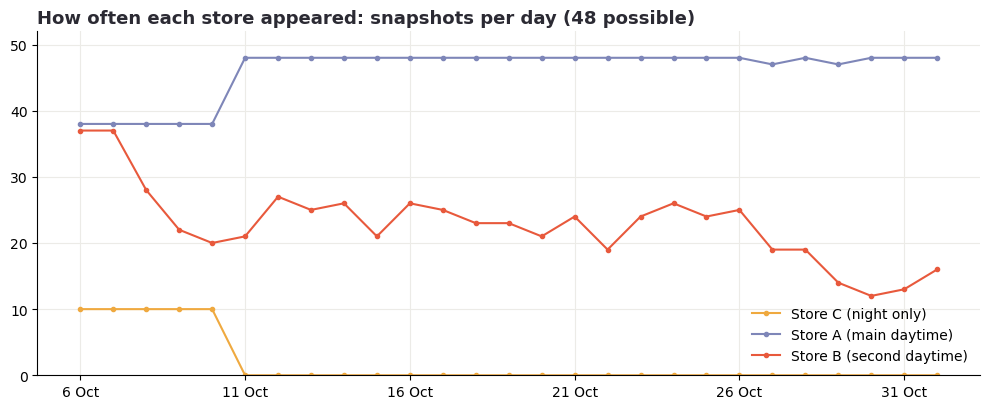

In [2]:
times = sorted(snap.snapshot_time.unique())
window = [t for t in times if D0 <= t[:10] <= D1]
win = snap[snap.snapshot_time.isin(window)].copy()
gaps = pd.Series(pd.to_datetime(window)).diff().dt.total_seconds().div(60).dropna()

r = runs[runs.saved_at.notna()].copy()
r["t"] = pd.to_datetime(r.saved_at, format="%Y%m%d_%H%M%S")
r["reported"] = r.listing_totals.fillna("").map(lambda v: max([int(x) for x in v.split("|") if x], default=np.nan))
r["complete"] = r.reported.notna() & (r.saved.astype(int) >= r.reported)
matched = pd.merge_asof(pd.DataFrame({"t": pd.to_datetime(window), "snapshot_time": window}), r.sort_values("t")[["t", "complete"]],
                        on="t", direction="nearest", tolerance=pd.Timedelta("120s"))
complete = set(matched[matched.complete.eq(True)].snapshot_time)

display(pd.Series({
    "Full days in window": len({t[:10] for t in window}),
    "Snapshots": len(window),
    "Complete snapshots": len(complete),
    "Partial snapshots": len(window) - len(complete),
    "Median gap (min)": round(gaps.median(), 1),
    "Longest gap (min)": round(gaps.max(), 1),
    "Duplicate rows": int(win.duplicated(["snapshot_time", "product_id"]).sum()),
    "Missing stock values": int(win.stock.isna().sum()),
    "Missing prices": int(win.listed_price.isna().sum()),
}).to_frame("value"))

labels = {"A": "Store A (main daytime)", "B": "Store B (second daytime)", "C": "Store C (night only)"}
seen = win.assign(day=win.snapshot_time.str[:10]).groupby(["day", "store_id"]).snapshot_time.nunique().unstack(fill_value=0).rename(columns=labels)
ax = seen.plot(marker="o", ms=3, color=[{"Store A (main daytime)": BLUE, "Store B (second daytime)": ACCENT, "Store C (night only)": GOLD}[x] for x in seen.columns])
ax.set_title("How often each store appeared: snapshots per day (48 possible)"); ax.set_xlabel(""); ax.set_ylim(0, 52); ax.legend(frameon=False)
ax.set_xticks(range(0, len(seen), 5)); ax.set_xticklabels(pd.to_datetime(seen.index[::5]).strftime("%-d %b"))
save("store_visibility")

### 0.3 Turn stock changes into estimated sales
**Packs sold = the fall in stock for the same product at the same store between two snapshots.** Rises are restocks and never count. Four artifacts are stock corrections rather than orders, so they're removed:

- **Morning reset:** stock is otherwise still overnight. Between 04:00 and 06:00 the main store sets many products to one value, usually 12.
- **Late reset:** on some days the reset comes later, so 2+ products at one store each falling 5+ units to exactly 12 in the same half-hour are also removed. Across the window this only happens on 1 November.
- **Closing adjustment:** Store B's stock falls across many products in the 23:00–23:30 interval.
- **One-off correction:** one product falling 30+ units in a half-hour. The next largest drop is 19.

In [3]:
inv = snap.pivot(index="snapshot_time", columns="product_id", values="stock").reindex(times)
sto = snap.pivot(index="snapshot_time", columns="product_id", values="store_id").reindex(times)
pri = snap.pivot(index="snapshot_time", columns="product_id", values="listed_price").reindex(times)
products = list(inv.columns)
pid = {p: i for i, p in enumerate(products)}

idx = np.array([k for k in range(1, len(times)) if D0 <= times[k][:10] <= D1])
start, end = inv.values[idx - 1], inv.values[idx]
store_a, store_b, price_a = sto.values[idx - 1], sto.values[idx], pri.values[idx - 1]
iv_day = np.array([times[k][:10] for k in idx])
iv_hour = np.array([int(times[k - 1][11:13]) for k in idx])
iv_hm = np.array([times[k - 1][11:16] for k in idx])

listed = ~np.isnan(start)
valid = listed & ~np.isnan(end) & (store_a == store_b) & (start > 0)     # a sale can be measured here
S = np.where(valid, np.maximum(start - end, 0), np.nan)

removed = {}
mask = np.isin(iv_hour, [4, 5])
removed["Morning reset"] = np.nansum(S[mask]); S[mask] = np.where(valid[mask], 0, np.nan)
removed["Late reset"] = 0.0
late = (S >= 5) & (end == 12)
for t_ in np.where(late.sum(1) >= 2)[0]:
    for st_ in set(store_a[t_][late[t_]]):
        hit = late[t_] & (store_a[t_] == st_)
        if hit.sum() >= 2:
            removed["Late reset"] += S[t_][hit].sum(); S[t_][hit] = 0
mask = S >= 30
removed["One-off correction"] = S[mask].sum(); S[mask] = 0
mask = (iv_hm >= "23:00") & (iv_hm < "23:30")
closing = np.outer(mask, np.ones(S.shape[1], bool)) & (store_a == "B") & valid
removed["Closing adjustment"] = S[closing].sum(); S[closing] = 0

def litres(v):
    if re.search(r"\d\s*(g|kg)$", v.strip()):
        return 0.0
    m = re.match(r"(?:(\d+)\s*x\s*)?([\d.]+)\s*(ml|ltr)", v)
    return int(m.group(1) or 1) * float(m.group(2)) * (0.001 if m.group(3) == "ml" else 1.0)

def kilograms(v):
    m = re.match(r"(?:(\d+)\s*x\s*)?([\d.]+)\s*(g|kg)", v)
    return int(m.group(1) or 1) * float(m.group(2)) * (0.001 if m.group(3) == "g" else 1.0)

def short(name, variant):
    n = re.sub(r"\s*\(.*?\)", "", name).replace(" Milk", "").replace(" Organic", "").replace(" Pasteurised Standardized", "")
    n = n.replace(" High Protein", " Protein").replace(" Homogenised", "").replace(" Farm Fresh", "")
    return f"{n[:34].strip()} {variant}"

meta = snap.drop_duplicates("product_id", keep="last").set_index("product_id")[["product_name", "brand", "variant"]].reindex(products)
meta["litres"] = meta.variant.map(litres)
meta["by_weight"] = meta.litres.eq(0)
meta["protein"] = meta.product_name.str.lower().str.contains("protein")
meta["need"] = np.select([meta.protein, meta.product_name.str.lower().str.contains("oat|almond|soy|coconut|plant"), meta.product_name.str.lower().str.contains("probiotic|yakult")], ["Protein", "Plant-based", "Probiotic"], "Regular milk")
meta["pack_band"] = np.where(meta.by_weight, "By weight", np.where(meta.litres <= .3, "≤ 300 ml", np.where(meta.litres <= .6, "400–500 ml", "1 litre")))
meta["label"] = [short(n, v) for n, v in zip(meta.product_name, meta.variant)]
dupes = meta.label.duplicated(keep=False)                               # different products that shorten to one name
meta.loc[dupes, "label"] = [f"{n.replace(' Organic', '').replace(' Milk', '')[:34]} {v}" for n, v in zip(meta.product_name[dupes], meta.variant[dupes])]

rows, cols = np.where(S > 0)
sales = pd.DataFrame({"product_id": np.array(products)[cols], "store": store_a[rows, cols], "packs": S[rows, cols],
                      "price": price_a[rows, cols], "day": iv_day[rows], "hour": iv_hour[rows]})
sales["value"] = sales.packs * sales.price
sales = sales.join(meta, on="product_id")
sales["lit"] = sales.packs * sales.litres

days = sorted({str(d) for d in iv_day})
n_iv = pd.Series(iv_day).value_counts().reindex(days)
ND = len(idx) / 48
TU, TR, TL = sales.packs.sum(), sales.value.sum(), sales.lit.sum()
units = sales.groupby("product_id").packs.sum().reindex(products, fill_value=0)
value = sales.groupby("product_id").value.sum().reindex(products, fill_value=0)

print(f"Estimated packs: {TU:,.0f}  |  Estimated sales value: {rupee(TR)}  |  Litres: {TL:,.0f}")
print("Removed as artifacts:", {k: int(v) for k, v in removed.items()})

Estimated packs: 6,407  |  Estimated sales value: ₹4,02,405  |  Litres: 3,246
Removed as artifacts: {'Morning reset': 3455, 'Late reset': 178, 'One-off correction': 50, 'Closing adjustment': 408}


## Step 1. Market distribution

### 1.1 Brand share: packs vs sales value
A brand's share of packs and its share of value can differ a lot, so both are shown.

,packs,value,% packs,% value,value per pack
brand,,,,,
Amul,1429.0,68473.0,22.3,17.0,48.0
Akshayakalpa Organic,1357.0,97592.0,21.2,24.3,72.0
Provilac,899.0,116641.0,14.0,29.0,130.0
Nandini,731.0,23486.0,11.4,5.8,32.0
Arokya,452.0,15246.0,7.1,3.8,34.0
Heritage,413.0,12890.0,6.4,3.2,31.0
Sids Farm,315.0,19263.0,4.9,4.8,61.0
Country Delight,308.0,14995.0,4.8,3.7,49.0
Nandini Goodlife,171.0,6734.0,2.7,1.7,39.0


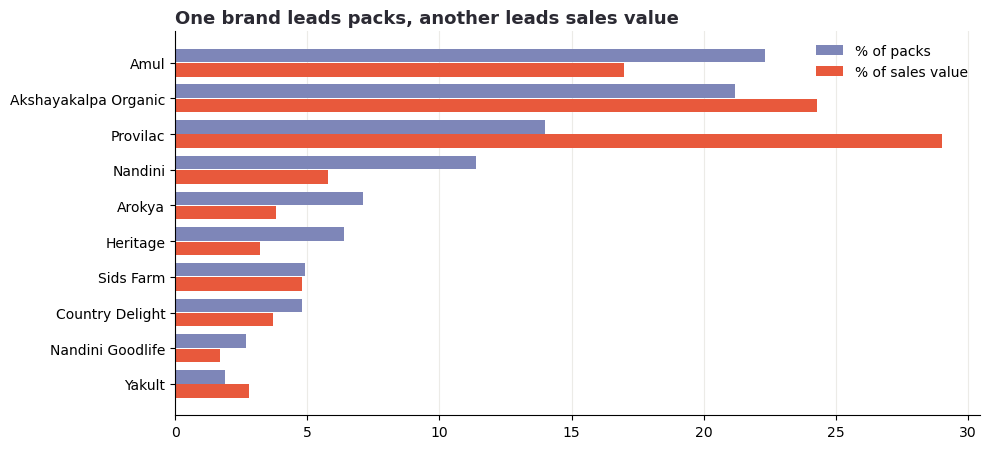

Amul leads packs (22.3%). Provilac leads value (29.0%), at ₹130 a pack against ₹63 for the category.


In [4]:
brands = sales.groupby("brand").agg(packs=("packs", "sum"), value=("value", "sum")).sort_values("packs", ascending=False)
brands["% packs"] = (brands.packs / TU * 100).round(1)
brands["% value"] = (brands.value / TR * 100).round(1)
brands["value per pack"] = (brands.value / brands.packs).round(0)
display(brands.round({"packs": 0, "value": 0}))

top = brands.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.6)); y = np.arange(len(top))
ax.barh(y + .2, top["% packs"], .38, color=BLUE, label="% of packs"); ax.barh(y - .2, top["% value"], .38, color=ACCENT, label="% of sales value")
ax.set_yticks(y); ax.set_yticklabels(top.index); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True); ax.legend(frameon=False)
ax.set_title("One brand leads packs, another leads sales value")
save("brand_share")
lead_u, lead_r = brands.packs.idxmax(), brands.value.idxmax()
print(f"{lead_u} leads packs ({brands.loc[lead_u, '% packs']}%). {lead_r} leads value ({brands.loc[lead_r, '% value']}%), "
      f"at {rupee(brands.loc[lead_r, 'value per pack'])} a pack against {rupee(TR / TU)} for the category.")

### 1.2 Market share treemap
Each box is a brand, sized by its share. Comparing the two maps shows which brands earn more value than their pack share suggests. Brands below 2% are grouped as "Other brands".

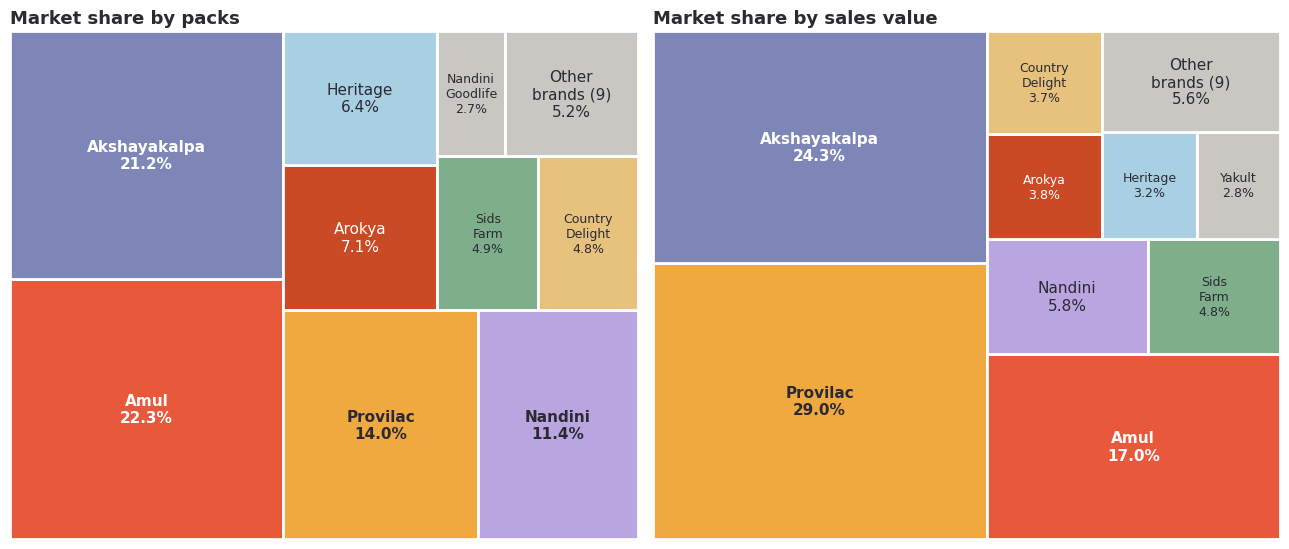

In [5]:
try:
    import squarify
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "squarify"], check=True)
    import squarify

brand_color = dict(zip(brands.index[:8], PALETTE))
DARK = {"#E8593C", "#7E86B8", "#C94A24"}

def treemap(ax, column, title):
    share = (brands[column] / brands[column].sum() * 100).sort_values(ascending=False)
    big, rest = share[share >= 2], share[share < 2]
    names_ = list(big.index) + ([f"Other brands ({len(rest)})"] if len(rest) else [])
    sizes = list(big.values) + ([rest.sum()] if len(rest) else [])
    fills = [brand_color.get(n, GREY) for n in names_]
    tiles = squarify.squarify(squarify.normalize_sizes(sizes, 100, 100), 0, 0, 100, 100)
    for n, v, co, t in zip(names_, sizes, fills, tiles):
        ax.add_patch(plt.Rectangle((t["x"], t["y"]), t["dx"], t["dy"], facecolor=co, edgecolor="white", linewidth=2))
        ax.text(t["x"] + t["dx"] / 2, t["y"] + t["dy"] / 2, f"{n.replace(' Organic', '').replace(' ', chr(10), 1)}\n{v:.1f}%", ha="center", va="center",
                fontsize=11 if v >= 5 else 9, color="white" if co in DARK else INK, fontweight="bold" if v >= 10 else "normal")
    ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off"); ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
treemap(axes[0], "packs", "Market share by packs")
treemap(axes[1], "value", "Market share by sales value")
save("market_share_treemap")

### 1.3 Brand mix by day
A changing mix doesn't always mean changing demand: Store B's visibility moves the brands sold mainly through it.

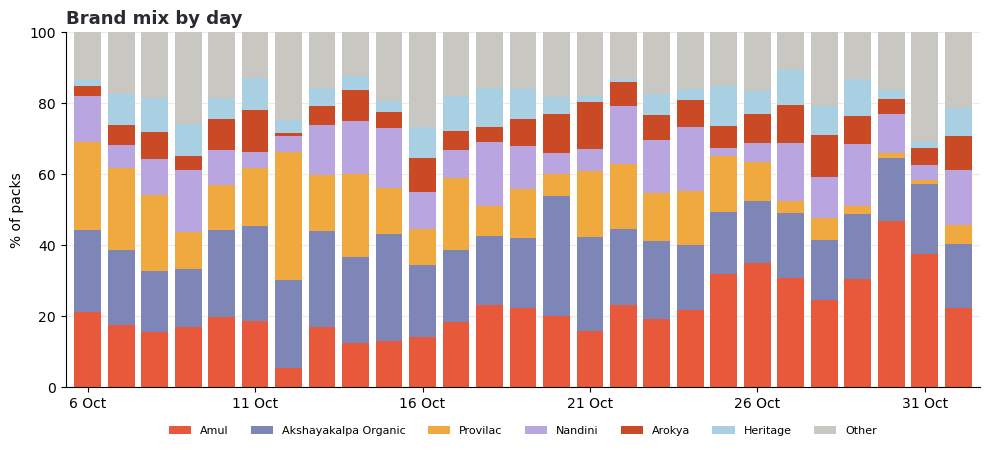

99% of Provilac's packs came through Store B, so its share moves with what was visible.


In [6]:
six = list(brands.index[:6])
mix = sales.assign(b=sales.brand.where(sales.brand.isin(six), "Other")).groupby(["day", "b"]).packs.sum().unstack(fill_value=0)[six + ["Other"]]
share = mix.div(mix.sum(axis=1), axis=0) * 100
ax = share.plot(kind="bar", stacked=True, width=.8, color=PALETTE[:6] + [GREY], figsize=(10, 4.6))
ax.set_xticks(range(0, len(share), 5)); ax.set_xticklabels(pd.to_datetime(share.index[::5]).strftime("%-d %b"), rotation=0)
ax.set_ylabel("% of packs"); ax.set_xlabel(""); ax.set_ylim(0, 100); ax.legend(frameon=False, ncol=7, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.08))
ax.set_title("Brand mix by day")
save("brand_mix_daily")
by_store = sales[sales.brand == "Provilac"].groupby("store").packs.sum()
print(f"{by_store.get('B', 0) / by_store.sum():.0%} of Provilac's packs came through Store B, so its share moves with what was visible.")

### 1.4 Top 10 products
The first table ranks products by total packs. The second ranks them by **average packs per sellable day**, so a product isn't marked down for being hidden or out of stock. A sellable day is 34 half-hours between 06:00 and 23:00 when the product was listed and in stock, which keeps the comparison fair because Store B mostly appears in the daytime. Products with fewer than 3 sellable days are left out. The table also shows the plain average across every day in the period.

In [7]:
median_price = win.groupby("product_id").listed_price.median()
in_window = [p for p in products if p in median_price.index]

ok = win[win.snapshot_time.isin(complete)].assign(in_stock=lambda f: f.stock > 0)
fill_product = ok.groupby("product_id").in_stock.mean()
top10 = units.sort_values(ascending=False, kind="stable").index[:10].tolist()

def unit_price(p):
    return f"₹{median_price[p] / kilograms(meta.variant[p]):.0f}/kg" if meta.by_weight[p] else f"₹{median_price[p] / meta.litres[p]:.0f}/L"

display(pd.DataFrame([{"Rank": i + 1, "Product": meta.label[p], "Brand": meta.brand[p], "Packs": int(units[p]), "Sales value": rupee(value[p]),
                       "Unit price": unit_price(p), "In stock": f"{fill_product.get(p, 0):.0%}"} for i, p in enumerate(top10)]).set_index("Rank"))

daytime = (iv_hour >= 6) & (iv_hour < 23)
trading_days = pd.Series((~np.isnan(S[daytime])).sum(0) / 34, index=products)        # 34 half-hours in a 06:00-23:00 trading day
day_packs = pd.Series(np.nansum(S[daytime], axis=0), index=products)
avg = pd.DataFrame({"packs": units, "value": value, "day_packs": day_packs, "trading": trading_days})
avg = avg[avg.trading >= 3]
avg["rate"] = avg.day_packs / avg.trading
top_avg = avg.sort_values("rate", ascending=False, kind="stable").head(10)
display(pd.DataFrame([{"Rank": i + 1, "Product": meta.label[p], "Brand": meta.brand[p], "Avg packs per sellable day": round(r_.rate, 1),
                       "Sellable days": round(r_.trading, 1), "Avg packs per day, all days": round(r_.packs / ND, 1),
                       "Avg value per day, all days": rupee(r_.value / ND), "Total packs": int(r_.packs)} for i, (p, r_) in enumerate(top_avg.iterrows())]).set_index("Rank"))

,Product,Brand,Packs,Sales value,Unit price,In stock
Rank,,,,,,
1,Amul Taaza Toned 500 ml,Amul,301,"₹8,729",₹58/L,75%
2,Akshayakalpa Cow (Pasteurized) 500 ml,Akshayakalpa Organic,295,"₹14,111",₹96/L,86%
3,Akshayakalpa Amrutha A2 500 ml,Akshayakalpa Organic,271,"₹15,155",₹112/L,84%
4,Nandini Toned 500 ml,Nandini,270,"₹6,396",₹48/L,92%
5,Provilac Cacao 26g Protein 250 g,Provilac,239,"₹35,850",₹600/kg,92%
6,Arokya Full Cream 500 ml,Arokya,234,"₹9,360",₹80/L,92%
7,Amul Gold Full Cream 500 ml,Amul,231,"₹7,763",₹68/L,87%
8,Arokya Toned 500 ml,Arokya,218,"₹5,886",₹54/L,93%
9,Akshayakalpa A2 Cow 500 ml,Akshayakalpa Organic,203,"₹10,150",₹100/L,80%


,Product,Brand,Avg packs per sellable day,Sellable days,"Avg packs per day, all days","Avg value per day, all days",Total packs
Rank,,,,,,,
1,Provilac Cacao 26g Protein 250 g,Provilac,25.9,9.2,8.9,"₹1,330",239
2,Provilac 50g Protein 500 ml,Provilac,24.8,7.9,7.3,"₹1,096",197
3,Provilac 25g Protein 250 ml,Provilac,20.5,7.9,6.0,₹537,161
4,Akshayakalpa Kesar Elaichi Protein 250 ml,Akshayakalpa Organic,15.7,5.7,3.4,₹379,93
5,Amul Taaza Toned 500 ml,Amul,15.6,18.8,11.2,₹324,301
6,Nandini Shubham Toned 1 ltr,Nandini,13.3,5.0,2.4,₹127,66
7,Akshayakalpa Strawberry Protein 250 ml,Akshayakalpa Organic,13.2,6.7,3.3,₹363,89
8,Akshayakalpa Cow (Pasteurized) 500 ml,Akshayakalpa Organic,13.2,21.7,10.9,₹523,295
9,Akshayakalpa Amrutha A2 500 ml,Akshayakalpa Organic,12.3,21.4,10.1,₹562,271


## Step 2. Pricing

### 2.1 Price segments
Products are grouped by listed price per litre, using each product's median price. Products labelled by weight (g/kg) have no defensible per-litre price, so they form their own group.

,products,packs,lit,value,% packs,% litres,% value
segment,,,,,,,
Value (<₹60/L),11,1418.0,752.0,40306.0,22.1,23.2,10.0
Mainstream (₹60–80),16,1169.0,718.0,51994.0,18.2,22.1,12.9
Premium (₹80–150),47,2407.0,1425.0,143038.0,37.6,43.9,35.5
Specialty (₹150+),28,1092.0,351.0,120557.0,17.0,10.8,30.0
Weight (₹/kg),3,321.0,0.0,46510.0,5.0,0.0,11.6


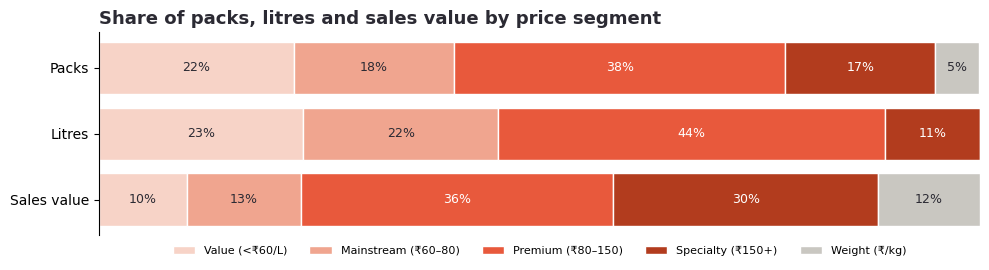

Above ₹150/L: 17% of packs, 30% of sales value.
Protein drinks: 22 products, 24% of packs, 40% of sales value.


In [8]:
SEGMENTS = ["Value (<₹60/L)", "Mainstream (₹60–80)", "Premium (₹80–150)", "Specialty (₹150+)", "Weight (₹/kg)"]
def segment(p):
    if meta.by_weight[p]:
        return SEGMENTS[4]
    ppl = median_price[p] / meta.litres[p]
    return SEGMENTS[0] if ppl < 60 else SEGMENTS[1] if ppl < 80 else SEGMENTS[2] if ppl < 150 else SEGMENTS[3]

catalog = meta.loc[in_window].assign(price=median_price, packs=units, value=value)
catalog["segment"] = [segment(p) for p in catalog.index]
catalog["lit"] = catalog.packs * catalog.litres
seg = catalog.groupby("segment").agg(products=("packs", "size"), packs=("packs", "sum"), lit=("lit", "sum"), value=("value", "sum")).loc[SEGMENTS]
seg["% packs"] = (seg.packs / TU * 100).round(1); seg["% litres"] = (seg.lit / TL * 100).round(1); seg["% value"] = (seg.value / TR * 100).round(1)
display(seg.round({"packs": 0, "lit": 0, "value": 0}))

fig, ax = plt.subplots(figsize=(10, 2.8)); colors = ["#F7D3C7", "#F0A58F", "#E8593C", "#B23C1E", GREY]
for y, col, name in zip([2, 1, 0], ["% packs", "% litres", "% value"], ["Packs", "Litres", "Sales value"]):
    left = 0
    for s, co in zip(SEGMENTS, colors):
        v = seg.loc[s, col]; ax.barh(y, v, left=left, color=co, edgecolor="white", label=s if y == 2 else None)
        if v > 4:
            ax.text(left + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white" if co in colors[2:4] else INK)
        left += v
ax.set_yticks([2, 1, 0]); ax.set_yticklabels(["Packs", "Litres", "Sales value"]); ax.set_xlim(0, 100); ax.set_xticks([]); ax.grid(False); ax.spines["bottom"].set_visible(False)
ax.legend(frameon=False, ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(.5, 0)); ax.set_title("Share of packs, litres and sales value by price segment")
save("price_segments")

protein = catalog[catalog.protein]
print(f"Above ₹150/L: {seg.loc[SEGMENTS[3], '% packs']:.0f}% of packs, {seg.loc[SEGMENTS[3], '% value']:.0f}% of sales value.")
print(f"Protein drinks: {len(protein)} products, {protein.packs.sum() / TU:.0%} of packs, {protein.value.sum() / TR:.0%} of sales value.")

### 2.2 Price ladder
Each dot is a volume-labelled product that sold: price per litre on a log scale against estimated litres sold.

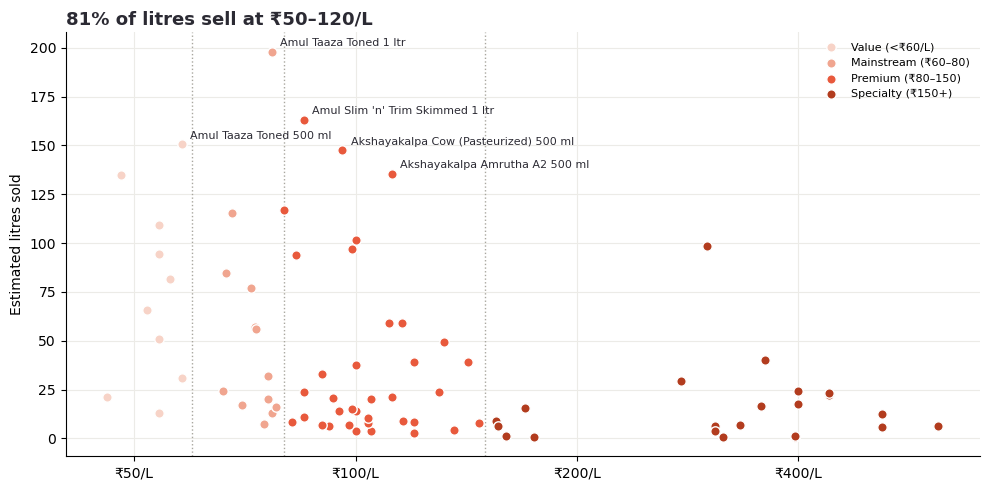

In [9]:
lad = catalog[(catalog.packs > 0) & ~catalog.by_weight].assign(ppl=lambda f: f.price / f.litres)
fig, ax = plt.subplots(figsize=(10, 5))
for s, co in zip(SEGMENTS[:4], colors):
    g = lad[lad.segment == s]; ax.scatter(g.ppl, g.lit, s=46, color=co, edgecolor="white", label=s, zorder=3)
for edge in (60, 80, 150):
    ax.axvline(edge, color="#A9A79F", lw=1, ls=":")
for _, row in lad.sort_values("lit", ascending=False).head(5).iterrows():
    ax.annotate(row.label, (row.ppl, row.lit), xytext=(6, 4), textcoords="offset points", fontsize=8, color=INK)
ax.set_xscale("log"); ax.set_xticks([50, 100, 200, 400]); ax.set_xticklabels(["₹50/L", "₹100/L", "₹200/L", "₹400/L"]); ax.minorticks_off()
ax.set_ylabel("Estimated litres sold"); ax.legend(frameon=False, fontsize=8); ax.grid(axis="x", visible=True)
band = lad[lad.ppl.between(50, 120)].lit.sum() / lad.lit.sum()
ax.set_title(f"{band:.0%} of litres sell at ₹50–120/L")
save("price_ladder")

### 2.3 Pack sizes
Pack-size mix, plus four milks sold in both 500 ml and 1 litre, to compare the share of litres and the price per litre.

In [10]:
def size_band(p):
    if meta.by_weight[p]:
        return "By weight"
    l = meta.litres[p]
    return "≤ 300 ml" if l <= .3 else "400–500 ml" if l <= .6 else "1 litre"

catalog["band"] = [size_band(p) for p in catalog.index]
bands = catalog.groupby("band").agg(products=("packs", "size"), packs=("packs", "sum"), lit=("lit", "sum")).loc[["≤ 300 ml", "400–500 ml", "1 litre", "By weight"]]
bands["% packs"] = (bands.packs / TU * 100).round(1); bands["% litres"] = (bands.lit / TL * 100).round(1)
display(bands.round({"packs": 0, "lit": 0}))
print(f"The exact 500 ml size is {catalog[catalog.variant == '500 ml'].packs.sum() / TU:.0%} of packs.")

def find(prefix, lo, hi):
    g = catalog[catalog.product_name.str.startswith(prefix) & catalog.litres.between(lo, hi)]
    return g.packs.idxmax() if len(g) else None

rows_ = []
for small, large, name in [("Nandini Shubham", "Nandini Shubham", "Nandini Shubham Toned"), ("Nandini Toned Milk", "Nandini Toned Milk", "Nandini Toned"),
                           ("Amul Taaza Toned Milk", "Amul Taaza Homogenised Toned Milk", "Amul Taaza Toned"), ("Amul Gold Full Cream Milk", "Amul Gold Milk", "Amul Gold")]:
    a_, b_ = find(small, .45, .5), find(large, 1, 1)
    if a_ and b_:
        la, lb = catalog.lit[a_], catalog.lit[b_]
        rows_.append({"Milk": name, "Litres, 500 ml": round(la), "Litres, 1 L": round(lb), "% litres in 500 ml": round(la / (la + lb) * 100),
                      "₹/L, 500 ml": round(catalog.price[a_] / catalog.litres[a_]), "₹/L, 1 L": round(catalog.price[b_] / catalog.litres[b_])})
display(pd.DataFrame(rows_).set_index("Milk"))

,products,packs,lit,% packs,% litres
band,,,,,
≤ 300 ml,20,926.0,226.0,14.5,7.0
400–500 ml,48,4173.0,2033.0,65.1,62.6
1 litre,34,987.0,987.0,15.4,30.4
By weight,3,321.0,0.0,5.0,0.0


The exact 500 ml size is 53% of packs.


,"Litres, 500 ml","Litres, 1 L",% litres in 500 ml,"₹/L, 500 ml","₹/L, 1 L"
Milk,,,,,
Nandini Shubham Toned,94,66,59,54,52
Nandini Toned,135,21,87,48,46
Amul Taaza Toned,150,198,43,58,77
Amul Gold,116,94,55,68,83


## Step 3. Sales

### 3.1 Daily sales by store
**The lower level from 11 October isn't evidence of falling demand.** Store B was often hidden from this address's listings from 9 October, so its recorded sales fell.

238 packs a day  |  120 litres a day  |  ₹14,927 a day  |  ₹63 a pack


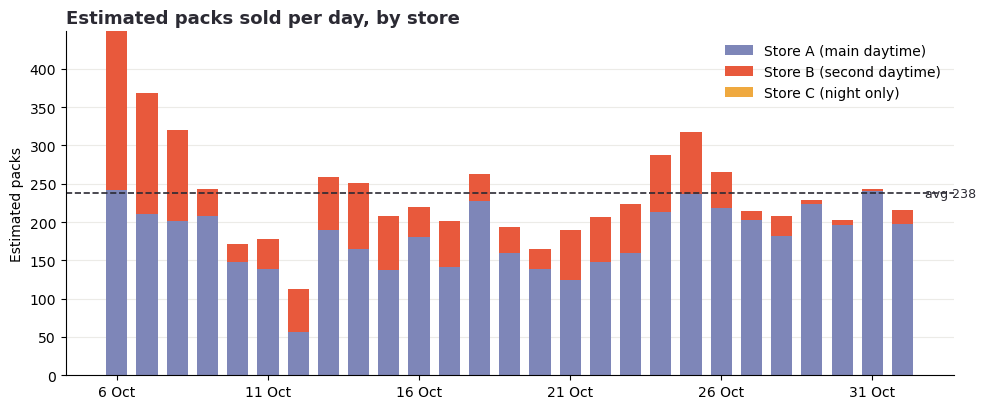

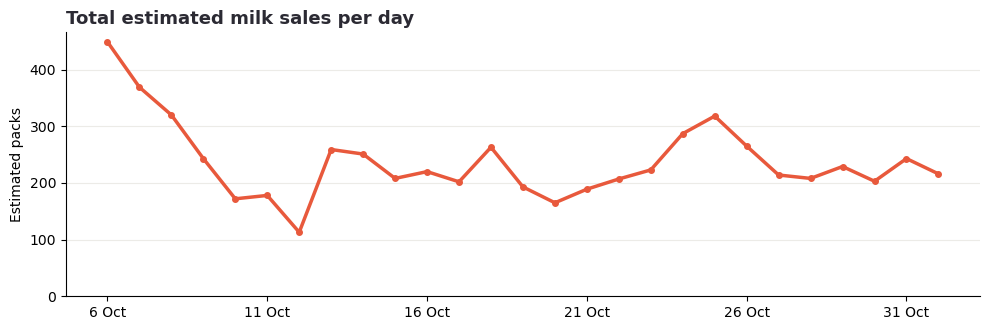

All stores: 311 a day on 6–10 Oct, 221 from 11 Oct.  Store B: 108 a day, then 45.


In [11]:
daily = sales.groupby(["day", "store"]).packs.sum().unstack(fill_value=0).reindex(days, fill_value=0)
for s in labels:
    if s not in daily:
        daily[s] = 0
total = daily.sum(axis=1)
print(f"{TU / ND:.0f} packs a day  |  {TL / ND:.0f} litres a day  |  {rupee(TR / ND)} a day  |  {rupee(TR / TU)} a pack")

fig, ax = plt.subplots(); x = np.arange(len(days)); bottom = np.zeros(len(days))
for s, co in zip(labels, [BLUE, ACCENT, GOLD]):
    ax.bar(x, daily[s], .7, bottom=bottom, color=co, label=labels[s]); bottom += daily[s].values
ax.axhline(TU / ND, color=INK, ls="--", lw=1.2); ax.text(len(days) - .4, TU / ND, f" avg {TU / ND:.0f}", va="center", fontsize=9, color=INK)
ax.set_xticks(x[::5]); ax.set_xticklabels(pd.to_datetime(days[::5]).strftime("%-d %b")); ax.set_ylabel("Estimated packs"); ax.legend(frameon=False)
ax.set_title("Estimated packs sold per day, by store")
save("daily_sales_by_store")

fig, ax = plt.subplots(figsize=(10, 3.4)); ax.plot(x, total.values, color=ACCENT, lw=2.5, marker="o", ms=4)
ax.set_xticks(x[::5]); ax.set_xticklabels(pd.to_datetime(days[::5]).strftime("%-d %b")); ax.set_ylim(0); ax.set_ylabel("Estimated packs")
ax.set_title("Total estimated milk sales per day")
save("daily_sales")

early, late = [d for d in days if d < "2026-10-11"], [d for d in days if d >= "2026-10-11"]
print(f"All stores: {total[early].mean():.0f} a day on 6–10 Oct, {total[late].mean():.0f} from 11 Oct.  "
      f"Store B: {daily['B'][early].mean():.0f} a day, then {daily['B'][late].mean():.0f}.")

### 3.2 Sales by week
Weeks run Monday to Sunday. The first chart compares weekly levels, using average packs a day because the first week has only 6 days. The second lays each week over the days of the week: if sales are cyclical, the lines should rise and fall together. Store A is shown separately because it's visible all day from 11 October, so changes in Store B's visibility don't affect it. Three full weeks can only hint at a cycle, not prove one.

,Days,Packs,Packs a day,Store A packs a day,Sales value a day
Week,,,,,
5 Oct–11 Oct,6,1731,288,192,"₹19,884"
12 Oct–18 Oct,7,1516,217,156,"₹14,390"
19 Oct–25 Oct,7,1582,226,169,"₹14,589"
26 Oct–1 Nov,7,1578,225,209,"₹11,463"


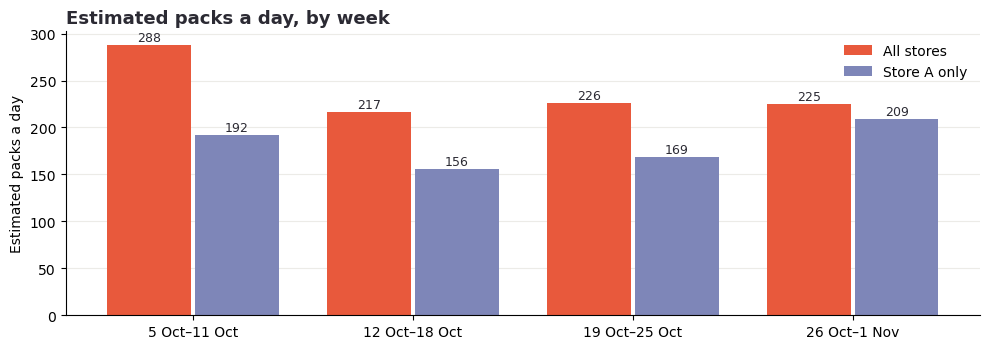

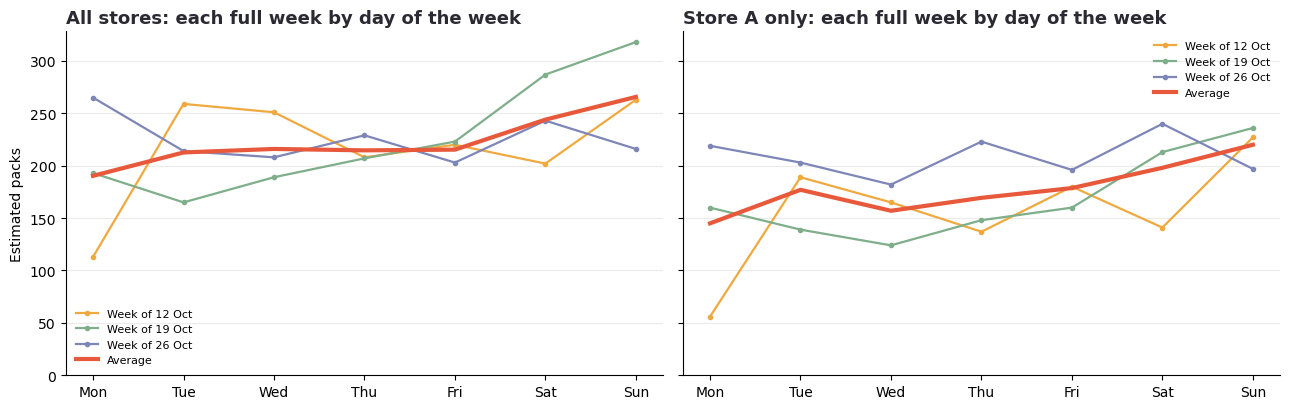

Store A's busiest day is Sun (220 packs on average) and its quietest is Mon (145).
Week-to-week repeat score, same weekday (1 = identical pattern, 0 = no link): all stores 0.12, Store A 0.32.


In [12]:
by_day = pd.DataFrame({"packs": total, "store_a": daily["A"], "value": sales.groupby("day").value.sum().reindex(days, fill_value=0)})
by_day.index = pd.to_datetime(by_day.index)
by_day["week"] = by_day.index.to_period("W-SUN").start_time
by_day["weekday"] = by_day.index.weekday
weekly = by_day.groupby("week").agg(Days=("packs", "size"), Packs=("packs", "sum"), store_a=("store_a", "sum"), value=("value", "sum"))
weekly["Packs a day"] = (weekly.Packs / weekly.Days).round(0).astype(int)
weekly["Store A packs a day"] = (weekly.store_a / weekly.Days).round(0).astype(int)
weekly["Sales value a day"] = (weekly.value / weekly.Days).map(rupee)
week_names = [f"{w:%-d %b}–{w + pd.Timedelta(days=6):%-d %b}" for w in weekly.index]
display(pd.DataFrame({"Week": week_names, "Days": weekly.Days.values, "Packs": weekly.Packs.round(0).astype(int).values, "Packs a day": weekly["Packs a day"].values,
                      "Store A packs a day": weekly["Store A packs a day"].values, "Sales value a day": weekly["Sales value a day"].values}).set_index("Week"))

fig, ax = plt.subplots(figsize=(10, 3.6)); pos = np.arange(len(weekly))
ax.bar(pos - .2, weekly["Packs a day"], .38, color=ACCENT, label="All stores"); ax.bar(pos + .2, weekly["Store A packs a day"], .38, color=BLUE, label="Store A only")
for k, (a_, b_) in enumerate(zip(weekly["Packs a day"], weekly["Store A packs a day"])):
    ax.text(k - .2, a_ + 4, str(a_), ha="center", fontsize=9, color=INK); ax.text(k + .2, b_ + 4, str(b_), ha="center", fontsize=9, color=INK)
ax.set_xticks(pos); ax.set_xticklabels(week_names); ax.set_ylabel("Estimated packs a day"); ax.legend(frameon=False)
ax.set_title("Estimated packs a day, by week")
save("sales_by_week")

full = by_day[by_day.groupby("week").packs.transform("size") == 7]
pattern = full.pivot(index="weekday", columns="week", values="packs")
pattern_a = full.pivot(index="weekday", columns="week", values="store_a")
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, table, name in zip(axes, [pattern, pattern_a], ["All stores", "Store A only"]):
    for w, co in zip(table.columns, [GOLD, "#7FAE8A", BLUE, "#B9A6E0"]):
        ax.plot(range(7), table[w], color=co, lw=1.6, marker="o", ms=3, label=f"Week of {w:%-d %b}")
    ax.plot(range(7), table.mean(axis=1), color=ACCENT, lw=3, label="Average")
    ax.set_xticks(range(7)); ax.set_xticklabels(day_names); ax.set_ylim(0); ax.set_title(f"{name}: each full week by day of the week"); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Estimated packs")
save("sales_day_of_week")

def repeat_score(table):
    a_ = table.iloc[:, :-1].values.ravel(); b_ = table.iloc[:, 1:].values.ravel()
    return np.corrcoef(a_, b_)[0, 1]
mean_a = pattern_a.mean(axis=1)
print(f"Store A's busiest day is {day_names[mean_a.idxmax()]} ({mean_a.max():.0f} packs on average) and its quietest is {day_names[mean_a.idxmin()]} ({mean_a.min():.0f}).")
print(f"Week-to-week repeat score, same weekday (1 = identical pattern, 0 = no link): all stores {repeat_score(pattern):.2f}, Store A {repeat_score(pattern_a):.2f}.")

### 3.3 Sales by hour
Half-hour drops are added into clock hours and averaged per day. Early-morning zeros come from the reset rule and from stock not moving overnight, so night sales are likely under-counted.

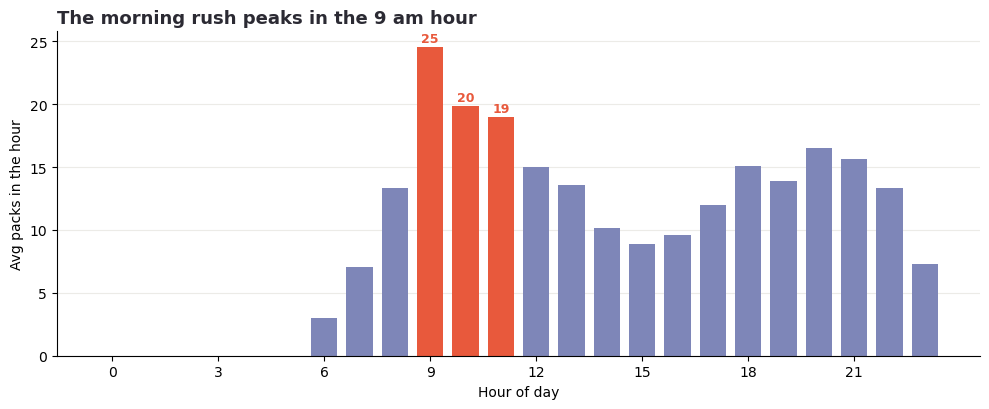

In [13]:
hours_seen = pd.Series(iv_hour).value_counts().reindex(range(24), fill_value=0) / 2
hourly = sales.groupby("hour").packs.sum().reindex(range(24), fill_value=0) / hours_seen.replace(0, np.nan)
hourly = hourly.fillna(0)
peaks = hourly.sort_values(ascending=False).index[:3]
fig, ax = plt.subplots()
ax.bar(hourly.index, hourly.values, .75, color=[ACCENT if h in peaks else BLUE for h in hourly.index])
for h in peaks:
    ax.text(h, hourly[h] + .4, f"{hourly[h]:.0f}", ha="center", fontsize=9, color=ACCENT, fontweight="bold")
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Hour of day"); ax.set_ylabel("Avg packs in the hour"); ax.set_title(f"The morning rush peaks in the {peaks[0]} am hour")
save("hour_of_day")

### 3.4 Weekday vs weekend
This uses 11 October onwards only, so store coverage is comparable.

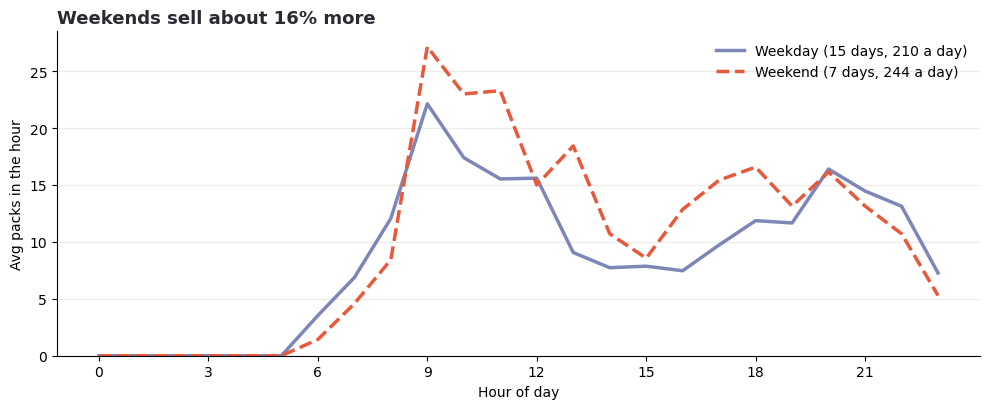

In [14]:
wk = sales[sales.day >= "2026-10-11"].copy()
kinds = {d: "Weekend" if pd.Timestamp(d).weekday() >= 5 else "Weekday" for d in days if d >= "2026-10-11"}
n_kind = pd.Series(kinds).value_counts()
wk["kind"] = wk.day.map(kinds)
per_day = wk.groupby("kind").packs.sum() / n_kind
curve = wk.groupby(["kind", "hour"]).packs.sum().unstack(0).reindex(range(24), fill_value=0).fillna(0) / n_kind

fig, ax = plt.subplots()
ax.plot(curve.index, curve.Weekday, color=BLUE, lw=2.5, label=f"Weekday ({n_kind.Weekday} days, {per_day.Weekday:.0f} a day)")
ax.plot(curve.index, curve.Weekend, color=ACCENT, lw=2.5, ls="--", label=f"Weekend ({n_kind.Weekend} days, {per_day.Weekend:.0f} a day)")
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Hour of day"); ax.set_ylabel("Avg packs in the hour"); ax.legend(frameon=False); ax.set_ylim(0)
ax.set_title(f"Weekends sell about {(per_day.Weekend / per_day.Weekday - 1):.0%} more")
save("weekday_weekend")

## Step 4. Inventory

### 4.1 Restocking
A restock is a rise of 2+ units between snapshots at one store. Snapshots can't separate deliveries from other stock adjustments.

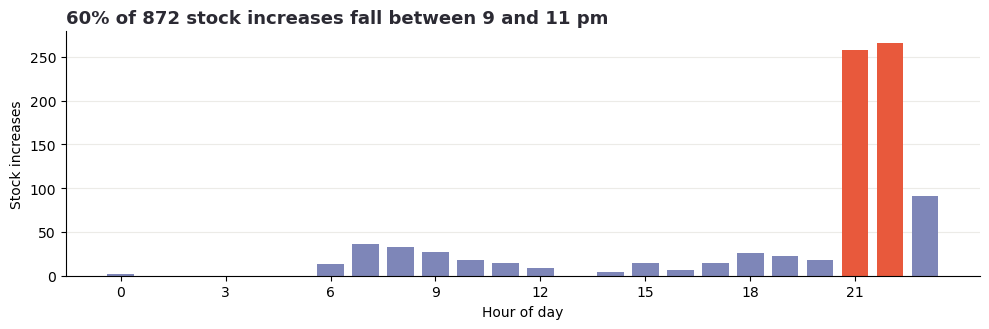

In [15]:
same = ~np.isnan(start) & ~np.isnan(end) & (store_a == store_b)
ups = np.where(same, end - start, np.nan)
restock_hour = pd.Series(iv_hour[np.where(ups >= 2)[0]]).value_counts().reindex(range(24), fill_value=0)
peak2 = restock_hour.sort_values(ascending=False).index[:2]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(restock_hour.index, restock_hour.values, .75, color=[ACCENT if h in peak2 else BLUE for h in restock_hour.index])
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Hour of day"); ax.set_ylabel("Stock increases")
share = (restock_hour[21] + restock_hour[22]) / restock_hour.sum()
ax.set_title(f"{share:.0%} of {restock_hour.sum()} stock increases fall between 9 and 11 pm")
save("restocks_by_hour")

### 4.2 Stockout duration
A stockout runs from the first snapshot at zero stock until stock returns, for one product at one store. Only episodes starting between 06:00 and 22:59 count. Any episode broken by a listing gap of over 1.5 hours is dropped, because what happened in the gap can't be seen.

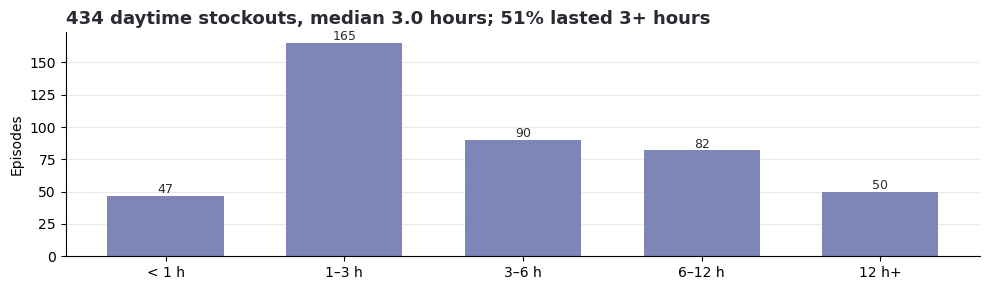

,Daytime stockouts,Median length (h)
Top seller,,
Amul Taaza Toned 500 ml,21,6.5
Amul Gold Full Cream 500 ml,12,4.8
Akshayakalpa A2 Cow 500 ml,18,3.5
Akshayakalpa Cow (Pasteurized) 500 ml,15,3.0
Akshayakalpa Amrutha A2 500 ml,15,2.5
Arokya Full Cream 500 ml,8,2.5
Provilac Cacao 26g Protein 250 g,3,2.0
Nandini Toned 500 ml,10,1.8
Arokya Toned 500 ml,6,1.8


In [16]:
episodes = []
for (p, st), g in win.sort_values("snapshot_time").groupby(["product_id", "store_id"]):
    begin = prev = None
    for t, q in zip(pd.to_datetime(g.snapshot_time), g.stock):
        if prev is not None and (t - prev).total_seconds() > 5400:
            begin = None
        if q <= 0 and begin is None:
            begin = t
        elif q > 0 and begin is not None:
            episodes.append((p, st, begin.hour, (t - begin).total_seconds() / 3600)); begin = None
        prev = t
ep = pd.DataFrame(episodes, columns=["product_id", "store", "start_hour", "hours"])
ep = ep[ep.start_hour.between(6, 22)]
edges = [0, 1, 3, 6, 12, 1e9]; names = ["< 1 h", "1–3 h", "3–6 h", "6–12 h", "12 h+"]
length = pd.cut(ep.hours, edges, right=False, labels=names).value_counts().reindex(names)

fig, ax = plt.subplots(figsize=(10, 3)); ax.bar(names, length.values, .65, color=BLUE)
for i, v in enumerate(length.values):
    ax.text(i, v + 2, str(v), ha="center", fontsize=9, color=INK)
ax.set_ylabel("Episodes"); ax.set_title(f"{len(ep)} daytime stockouts, median {ep.hours.median():.1f} hours; {(ep.hours >= 3).mean():.0%} lasted 3+ hours")
save("stockout_length")

med = ep[ep.product_id.isin(top10)].groupby("product_id").hours.agg(["size", "median"])
display(pd.DataFrame([{"Top seller": meta.label[p], "Daytime stockouts": int(med["size"].get(p, 0)), "Median length (h)": round(med["median"].get(p, np.nan), 1)}
                      for p in top10]).sort_values("Median length (h)", ascending=False).set_index("Top seller"))

## Step 5. Fill rates and availability

**Fill rate** is the share of listed product observations showing stock above zero, using complete snapshots only. It measures what the listing showed, not the chance that a shopper finds a given product. The **sales-weighted** version weights each product by its estimated packs + 1, so best sellers count more.

### 5.1 Overall and by brand

Listings in stock: 79.8% unweighted, 87.2% sales-weighted (1,117 complete snapshots)


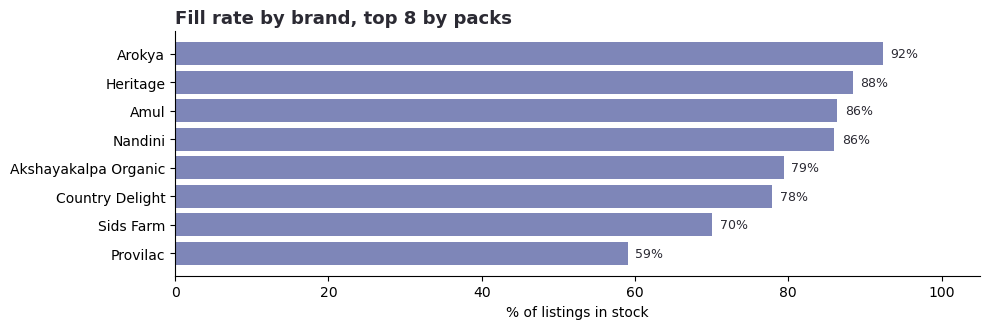

In [17]:
ok["weight"] = ok.product_id.map(units).fillna(0) + 1
ok["hour"] = ok.snapshot_time.str[11:13].astype(int); ok["day"] = ok.snapshot_time.str[:10]; ok = ok.join(meta[["label"]], on="product_id")
weighted = lambda f: (f.in_stock * f.weight).sum() / f.weight.sum()
print(f"Listings in stock: {ok.in_stock.mean():.1%} unweighted, {weighted(ok):.1%} sales-weighted ({len(complete):,} complete snapshots)")

fill_brand = ok.groupby("brand").in_stock.mean().reindex(brands.index[:8]).sort_values()
fig, ax = plt.subplots(figsize=(10, 3.4)); ax.barh(fill_brand.index, fill_brand * 100, color=BLUE)
for i, v in enumerate(fill_brand):
    ax.text(v * 100 + 1, i, f"{v:.0%}", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 105); ax.grid(axis="y", visible=False); ax.set_xlabel("% of listings in stock"); ax.set_title("Fill rate by brand, top 8 by packs")
save("fill_by_brand")

### 5.2 Daily availability

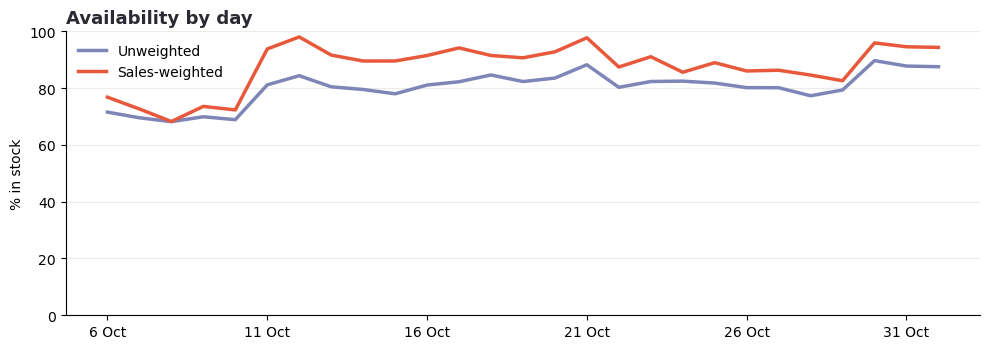

Lowest day: 2026-10-08 (68%).  Highest day: 2026-10-30 (90%).


In [18]:
fill_day = pd.DataFrame({"Unweighted": ok.groupby("day").in_stock.mean(), "Sales-weighted": ok.groupby("day")[["in_stock", "weight"]].apply(weighted)}) * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(range(len(fill_day)), fill_day.Unweighted, color=BLUE, lw=2.5, label="Unweighted"); ax.plot(range(len(fill_day)), fill_day["Sales-weighted"], color=ACCENT, lw=2.5, label="Sales-weighted")
ax.set_xticks(range(0, len(fill_day), 5)); ax.set_xticklabels(pd.to_datetime(fill_day.index[::5]).strftime("%-d %b")); ax.set_ylim(0, 100); ax.set_ylabel("% in stock"); ax.legend(frameon=False)
ax.set_title("Availability by day")
save("fill_by_day")
print(f"Lowest day: {fill_day.Unweighted.idxmin()} ({fill_day.Unweighted.min():.0f}%).  Highest day: {fill_day.Unweighted.idxmax()} ({fill_day.Unweighted.max():.0f}%).")

### 5.3 Hourly availability

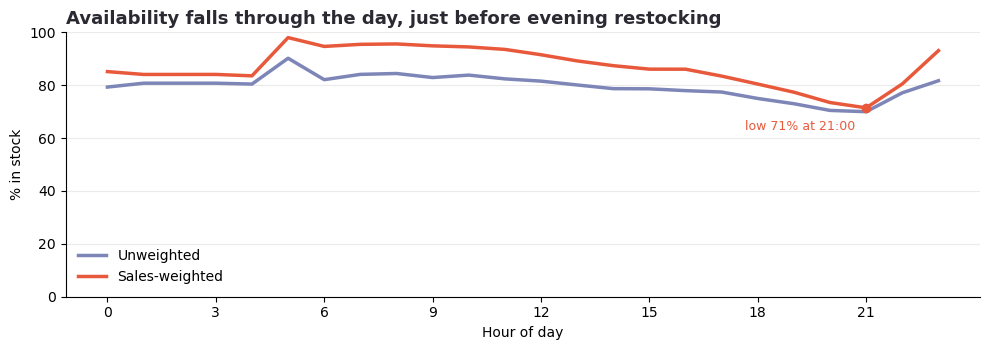

In [19]:
fill_hour = pd.DataFrame({"Unweighted": ok.groupby("hour").in_stock.mean(), "Sales-weighted": ok.groupby("hour")[["in_stock", "weight"]].apply(weighted)}) * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(fill_hour.index, fill_hour.Unweighted, color=BLUE, lw=2.5, label="Unweighted"); ax.plot(fill_hour.index, fill_hour["Sales-weighted"], color=ACCENT, lw=2.5, label="Sales-weighted")
low = fill_hour["Sales-weighted"].idxmin()
ax.scatter([low], [fill_hour["Sales-weighted"][low]], color=ACCENT, zorder=3); ax.annotate(f"low {fill_hour['Sales-weighted'][low]:.0f}% at {low}:00", (low, fill_hour["Sales-weighted"][low]), xytext=(-8, -16), textcoords="offset points", ha="right", fontsize=9, color=ACCENT)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Hour of day"); ax.set_ylim(0, 100); ax.set_ylabel("% in stock"); ax.legend(frameon=False, loc="lower left")
ax.set_title("Availability falls through the day, just before evening restocking")
save("fill_by_hour")

### 5.4 Fill rate by product
The least available among products with meaningful sales, then the full list.

In [20]:
fp = pd.DataFrame({"Product": meta.label, "Brand": meta.brand, "Packs": units.astype(int), "In stock %": (ok.groupby("product_id").in_stock.mean() * 100).round(1)}).dropna(subset=["In stock %"])
display(fp[fp.Packs >= 50].sort_values("In stock %").head(10).set_index("Product"))
scroll(fp.sort_values("Packs", ascending=False))

,Brand,Packs,In stock %
Product,,,
Akshayakalpa Kesar Elaichi Protein 250 ml,Akshayakalpa Organic,93,58.2
Akshayakalpa Strawberry Protein 250 ml,Akshayakalpa Organic,89,67.5
Provilac Kesar Elaichi 26g Protein 250 ml,Provilac,51,70.0
Amul Gold 1 ltr,Amul,94,73.4
Akshayakalpa Farm Fresh Cow 500 ml,Akshayakalpa Organic,75,73.8
Country Delight Buffalo Fresh 450 ml,Country Delight,131,74.3
Amul Taaza Toned 500 ml,Amul,301,74.7
Heritage Full Cream 500 ml,Heritage,64,78.2
Nandini N Pro Protein 500 ml,Nandini,102,79.7


Product,Brand,Packs,In stock %
Amul Taaza Toned 500 ml,Amul,301,74.7
Akshayakalpa Cow (Pasteurized) 500 ml,Akshayakalpa Organic,295,86.1
Akshayakalpa Amrutha A2 500 ml,Akshayakalpa Organic,271,83.8
Nandini Toned 500 ml,Nandini,270,91.7
Provilac Cacao 26g Protein 250 g,Provilac,239,92.3
Arokya Full Cream 500 ml,Arokya,234,91.9
Amul Gold Full Cream 500 ml,Amul,231,87.0
Arokya Toned 500 ml,Arokya,218,92.7
Akshayakalpa A2 Cow 500 ml,Akshayakalpa Organic,203,80.3
Amul Taaza Toned 1 ltr,Amul,198,100.0


### 5.5 Sales value potentially missed
Each out-of-stock half-hour is valued at the product's average in-stock sales at that hour (minimum 3 observations), at its median price. This is a modelled counterfactual, not an observed loss: shoppers may have bought a substitute, waited or gone elsewhere.

In [21]:
H = np.arange(24)
sold_q = np.zeros((24, len(products))); sold_n = np.zeros((24, len(products))); oos_n = np.zeros((24, len(products)))
out_now = listed & ~(start > 0)
has_sale = ~np.isnan(S)
for h in H:
    m = iv_hour == h
    sold_q[h] = np.nansum(S[m], axis=0); sold_n[h] = has_sale[m].sum(axis=0); oos_n[h] = out_now[m].sum(axis=0)
rate = np.divide(sold_q, sold_n, out=np.zeros_like(sold_q), where=sold_n >= 3)
lost_u = pd.Series((oos_n * rate).sum(axis=0), index=products)
lost_r = lost_u * median_price.reindex(products).fillna(0)
print(f"Potentially missed: {lost_u.sum():,.0f} packs and {rupee(lost_r.sum())}, or {rupee(lost_r.sum() / ND)} a day. "
      f"Modelled unmet demand: {lost_u.sum() / (lost_u.sum() + TU):.1%} of packs.")
order = lost_r.sort_values(ascending=False).index[:10]
display(pd.DataFrame({"Product": meta.label[order], "Packs missed": lost_u[order].round(0).astype(int), "Value missed": lost_r[order].map(rupee), "Packs sold": units[order].astype(int)}).set_index("Product"))

Potentially missed: 1,158 packs and ₹79,087, or ₹2,934 a day. Modelled unmet demand: 15.3% of packs.


,Packs missed,Value missed,Packs sold
Product,,,
Provilac 50g Protein 500 ml,43,"₹6,465",197
Provilac Cacao 26g Protein 250 g,32,"₹4,745",239
Akshayakalpa Kesar Elaichi Protein 250 ml,39,"₹4,309",93
Amul Taaza Toned 500 ml,145,"₹4,208",301
Provilac Kesar Elaichi 26g Protein 250 ml,26,"₹3,389",51
Amul Gold Premium Full Cream 1 ltr,34,"₹3,047",33
Amul Gold 1 ltr,35,"₹2,941",94
Provilac 25g Protein 250 ml,33,"₹2,934",161
Akshayakalpa Amrutha A2 500 ml,46,"₹2,603",271


## Step 6. Brand substitution

**Question:** when a brand runs short, whose sales rise? These are associations, not proof that shoppers switched.

**Method.** Brand A counts as **short** in a half-hour when at least 30% of its sales-weighted listed range is out of stock. For every pair of brands:

1. **Observed:** brand B's packs in the half-hours when A is short.
2. **Expected:** B's usual packs at the same hour of day when A is *not* short, scaled by that day's demand (other brands' sales rate) and by how much of B's own range could be sold in that half-hour.
3. **Lift** = observed ÷ expected − 1.
4. **90% interval:** 2,000 bootstrap resamples of days. A result is flagged when the interval excludes zero.

Pairs with expected sales below 5 packs or fewer than 10 half-hours show no interval, because there's too little data. Short periods mostly overnight are flagged, since little sells then.

In [22]:
rng = np.random.default_rng(SEED)
D = len(days); day_i = pd.Series(range(D), index=days)[iv_day].values
boot_w = np.stack([np.bincount(rng.integers(0, D, D), minlength=D) for _ in range(RESAMPLES)])     # resamples x days
n_day = n_iv.values.astype(float)

def by_day_hour(values):
    return np.bincount(day_i * 24 + iv_hour, weights=values, minlength=D * 24).reshape(D, 24)

def lift_stats(out_q, out_f, in_q, in_f, F):
    """Observed, expected and bootstrap lifts from day x hour totals."""
    hour_rate_q, hour_rate_f = in_q.sum(0), (in_f * F[:, None]).sum(0)
    usable = hour_rate_f > 0
    rate_ = np.divide(hour_rate_q, hour_rate_f, out=np.zeros(24), where=usable)
    obs, exp = out_q.sum(), ((out_f * F[:, None]).sum(0) * rate_)[usable].sum()
    return obs, exp

def boot_interval(out_q, out_f, in_q, in_f, F):
    fout = boot_w @ (out_f * F[:, None]); q = boot_w @ in_q; f = boot_w @ (in_f * F[:, None])
    e = (fout * np.divide(q, f, out=np.zeros_like(q), where=f > 0)).sum(1)
    o = boot_w @ out_q.sum(1)
    good = e > 0
    bt = np.sort(o[good] / e[good] - 1)
    lo, hi = bt[int(.05 * len(bt))], bt[int(.95 * len(bt)) - 1]
    p = min(1, 2 * (min((bt <= 0).sum(), (bt >= 0).sum()) + 1) / (len(bt) + 1))
    return lo, hi, p

def fdr(p):
    """Benjamini-Hochberg q-values."""
    p = np.asarray(p, float); o = np.argsort(p); q = p[o] * len(p) / (np.arange(len(p)) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]; out = np.empty(len(p)); out[o] = np.minimum(q, 1)
    return out

W = units.clip(lower=1)
brand_names = list(brands.index) + [b for b in sorted(meta.brand.unique()) if b not in brands.index]
b_cols = {b: np.where(meta.brand.values == b)[0] for b in brand_names}
B_sales = np.column_stack([np.nansum(S[:, b_cols[b]], axis=1) for b in brand_names])
B_short = np.full(B_sales.shape, np.nan); B_avail = np.zeros(B_sales.shape)
for j, b in enumerate(brand_names):
    cc, w = b_cols[b], W.values[b_cols[b]]
    tot = (listed[:, cc] * w).sum(1)
    B_short[:, j] = np.divide((out_now[:, cc] * w).sum(1), tot, out=np.full(len(tot), np.nan), where=tot > 0)
    B_avail[:, j] = (has_sale[:, cc] * w).sum(1) / w.sum()
hour_rate = rate[iv_hour]                                                 # each product's usual packs per half-hour, by hour
B_missed = np.column_stack([(out_now[:, b_cols[b]] * hour_rate[:, b_cols[b]]).sum(1) for b in brand_names])
day_brand = np.column_stack([np.bincount(day_i, weights=B_sales[:, j], minlength=D) for j in range(len(brand_names))])

records = []
for ia, A in enumerate(brand_names):
    short_ = B_short[:, ia]
    for ib, B_ in enumerate(brand_names):
        if ia == ib:
            continue
        keep = ~np.isnan(short_) & (B_avail[:, ib] > 0)
        is_out = keep & (short_ >= .3); is_in = keep & (short_ < .3)
        rest = day_brand.sum(1) - day_brand[:, ia] - day_brand[:, ib]
        m = rest.sum() / n_day.sum()
        F = (rest / n_day) / m if m else np.ones(D)
        out_q, in_q = by_day_hour(B_sales[:, ib] * is_out), by_day_hour(B_sales[:, ib] * is_in)
        out_f, in_f = by_day_hour(B_avail[:, ib] * is_out), by_day_hour(B_avail[:, ib] * is_in)
        obs, exp = lift_stats(out_q, out_f, in_q, in_f, F)
        n = int(is_out.sum())
        rec = {"Short brand": A, "Brand that may gain": B_, "Short half-hours": n, "Days short": int((by_day_hour(is_out.astype(float)).sum(1) > 0).sum()),
               "Night share": (iv_hour[is_out] < 6).mean() if n else np.nan, "Observed": obs, "Expected": exp,
               "Normal half-hours": int(is_in.sum()), "Packs A likely missed": B_missed[is_out, ia].sum()}
        if exp >= 5 and n >= 10:
            rec["Lift %"] = (obs / exp - 1) * 100
            lo, hi, p = boot_interval(out_q, out_f, in_q, in_f, F)
            rec.update({"Low %": lo * 100, "High %": hi * 100, "p": p})
        records.append(rec)
brand_all = pd.DataFrame(records)
tested = brand_all["Lift %"].notna()
brand_all.loc[tested, "q (FDR)"] = fdr(brand_all.loc[tested, "p"])
brand_all["Extra packs"] = brand_all.Observed - brand_all.Expected
brand_all["Flag"] = np.where(~tested, "too little data", np.where(brand_all["Low %"] > 0, "rose", np.where(brand_all["High %"] < 0, "fell", "no clear change")))
brand_all.to_csv(ROOT + "results/brand_substitution_all_pairs.csv", index=False)
print(f"{len(brand_all)} brand pairs: {tested.sum()} had enough data to test, {(brand_all.Flag == 'rose').sum()} rose, {(brand_all.Flag == 'fell').sum()} fell, "
      f"{(brand_all['q (FDR)'] < .1).sum()} survive a false-discovery check at 10%.")

462 brand pairs: 193 had enough data to test, 23 rose, 17 fell, 23 survive a false-discovery check at 10%.


### 6.1 All tested brand pairs
The full table, including pairs with too little data, is saved to `results/brand_substitution_all_pairs.csv`.

In [23]:
show = brand_all[tested].sort_values("Extra packs", ascending=False)[["Short brand", "Brand that may gain", "Short half-hours", "Days short", "Packs A likely missed", "Observed", "Expected", "Lift %", "Low %", "High %", "q (FDR)", "Flag"]].round({"Packs A likely missed": 0, "Observed": 0, "Expected": 1, "Lift %": 0, "Low %": 0, "High %": 0, "q (FDR)": 3})
scroll(show)

Short brand,Brand that may gain,Short half-hours,Days short,Packs A likely missed,Observed,Expected,Lift %,Low %,High %,q (FDR),Flag
Ave Natur,Amul,351,23,0.0,598.0,18.4,3149.0,2339.0,4866.0,0.017,rose
Ave Natur,Akshayakalpa Organic,354,23,0.0,613.0,64.0,857.0,657.0,1297.0,0.017,rose
Ave Natur,Provilac,271,23,0.0,627.0,90.4,593.0,421.0,972.0,0.017,rose
Worli Dairy,Amul,306,27,30.0,512.0,308.8,66.0,18.0,137.0,0.111,rose
Ave Natur,Nandini,350,23,0.0,311.0,125.9,147.0,73.0,235.0,0.017,rose
Ave Natur,Sids Farm,352,23,0.0,183.0,9.0,1942.0,1359.0,3449.0,0.017,rose
Country Delight,Nandini,372,21,80.0,407.0,236.0,72.0,18.0,167.0,0.104,rose
Ave Natur,Heritage,349,23,0.0,176.0,23.0,666.0,409.0,1068.0,0.017,rose
Epigamia,Akshayakalpa Organic,417,12,2.0,459.0,343.4,34.0,12.0,59.0,0.079,rose
Akshayakalpa Organic,Amul,227,21,177.0,372.0,272.0,37.0,0.0,84.0,0.487,rose


## Step 7. Product substitution, all products

**Method.** The same idea, one product against another. For every pair of products:

1. **Observed:** product B's packs in the half-hours when A is listed but out of stock.
2. **Expected:** B's usual packs at the same hour when A is in stock, scaled by that day's sales rate at B's main store, leaving out A and B.
3. **Lift, interval and data rules** are the same as step 6. These are associations, and with this many pairs some flagged results will be chance, so the table also shows a **false-discovery q-value**.

In [24]:
main_store = snap.groupby("product_id").store_id.agg(lambda s: s.value_counts().index[0]).reindex(products).values
stores = sorted(set(main_store))
P_day = np.zeros((D, len(products)))                                         # packs by day and product, for the store the sale happened at
store_day = {s: np.zeros(D) for s in stores}; prod_store_day = {s: np.zeros((D, len(products))) for s in stores}
S0 = np.nan_to_num(S)
for s in stores:
    at = store_a == s
    vals = S0 * at
    for d in range(D):
        prod_store_day[s][d] = vals[day_i == d].sum(0)
    store_day[s] = prod_store_day[s].sum(1)

A_out = out_now; A_in = listed & (start > 0)
pairs = []
dh = day_i * 24 + iv_hour
for ia, A in enumerate(products):
    if not A_out[:, ia].any():
        continue
    for ib, B_ in enumerate(products):
        if ia == ib:
            continue
        v = has_sale[:, ib]
        is_out, is_in = v & A_out[:, ia], v & A_in[:, ia]
        n = int(is_out.sum())
        if n == 0:
            continue
        s_ = main_store[ib]
        rest = store_day[s_] - prod_store_day[s_][:, ia] - prod_store_day[s_][:, ib]
        m = rest.sum() / n_day.sum()
        F = (rest / n_day) / m if m else np.ones(D)
        q = S0[:, ib]
        out_q = np.bincount(dh[is_out], weights=q[is_out], minlength=D * 24).reshape(D, 24)
        in_q = np.bincount(dh[is_in], weights=q[is_in], minlength=D * 24).reshape(D, 24)
        out_f = np.bincount(dh[is_out], minlength=D * 24).reshape(D, 24).astype(float)
        in_f = np.bincount(dh[is_in], minlength=D * 24).reshape(D, 24).astype(float)
        obs, exp = lift_stats(out_q, out_f, in_q, in_f, F)
        rec = {"A": A, "B": B_, "Out half-hours": n, "Days out": int((out_f.sum(1) > 0).sum()), "Night share": (iv_hour[is_out] < 6).mean(), "Observed": obs, "Expected": exp,
               "Normal half-hours": int(is_in.sum()), "Packs A likely missed": hour_rate[is_out, ia].sum()}
        if exp >= 5 and n >= 10:
            rec["Lift %"] = (obs / exp - 1) * 100
            lo, hi, p = boot_interval(out_q, out_f, in_q, in_f, F)
            rec.update({"Low %": lo * 100, "High %": hi * 100, "p": p})
        pairs.append(rec)
prod_all = pd.DataFrame(pairs)
tested_p = prod_all["Lift %"].notna()
prod_all.loc[tested_p, "q (FDR)"] = fdr(prod_all.loc[tested_p, "p"])
prod_all["Extra packs"] = prod_all.Observed - prod_all.Expected
prod_all["Flag"] = np.where(~tested_p, "too little data", np.where(prod_all["Low %"] > 0, "rose", np.where(prod_all["High %"] < 0, "fell", "no clear change")))
prod_all["Out of stock"] = prod_all.A.map(meta.label); prod_all["Product that may gain"] = prod_all.B.map(meta.label)
prod_all["Same need"] = prod_all.A.map(meta.need).values == prod_all.B.map(meta.need).values
prod_all["Same pack band"] = prod_all.A.map(meta.pack_band).values == prod_all.B.map(meta.pack_band).values
prod_all["Same store"] = prod_all.A.map(dict(zip(products, main_store))).values == prod_all.B.map(dict(zip(products, main_store))).values
prod_all.rename(columns={"A": "out_of_stock_id", "B": "may_gain_id"}).to_csv(ROOT + "results/product_substitution_all_pairs.csv", index=False)
print(f"{len(prod_all):,} product pairs had A out of stock while B could sell: {tested_p.sum():,} had enough data to test, {(prod_all.Flag == 'rose').sum()} rose, "
      f"{(prod_all.Flag == 'fell').sum()} fell, {(prod_all['q (FDR)'] < .1).sum()} survive a false-discovery check at 10%.")

6,890 product pairs had A out of stock while B could sell: 2,585 had enough data to test, 178 rose, 293 fell, 145 survive a false-discovery check at 10%.


### 7.1 All tested product pairs
The full table, including pairs with too little data, is saved to `results/product_substitution_all_pairs.csv`.

In [25]:
show = prod_all[tested_p].sort_values("Extra packs", ascending=False)[["Out of stock", "Product that may gain", "Out half-hours", "Days out", "Same need", "Same pack band", "Same store", "Packs A likely missed", "Observed", "Expected", "Lift %", "Low %", "High %", "q (FDR)", "Flag"]].round({"Packs A likely missed": 0, "Observed": 0, "Expected": 1, "Lift %": 0, "Low %": 0, "High %": 0, "q (FDR)": 3})
scroll(show)

Out of stock,Product that may gain,Out half-hours,Days out,Same need,Same pack band,Same store,Packs A likely missed,Observed,Expected,Lift %,Low %,High %,q (FDR),Flag
Akshayakalpa Slim 200 ml,Nandini Shubham Toned 500 ml,638,23,True,False,True,12.0,164.0,38.1,331.0,95.0,1295.0,0.059,rose
Ave Natur Barista Oat Beverage 1 ltr,Provilac 50g Protein 500 ml,184,22,False,False,True,0.0,127.0,8.8,1337.0,758.0,6251.0,0.036,rose
Akshayakalpa Slim 200 ml,Amul Gold Full Cream 500 ml,784,25,True,False,True,13.0,190.0,74.7,154.0,37.0,515.0,0.162,rose
Akshayakalpa Slim 200 ml,Nandini Toned 500 ml,812,25,True,False,True,14.0,211.0,101.3,108.0,-17.0,653.0,0.718,no clear change
Provilac Raw Cow 500 ml,Nandini Shubham Toned 500 ml,205,18,True,True,False,0.0,122.0,19.0,543.0,151.0,1049.0,0.036,rose
Ave Natur Barista Oat Beverage 1 ltr,Amul Gold Full Cream 500 ml,314,23,False,False,False,0.0,99.0,8.1,1121.0,628.0,2975.0,0.036,rose
Provilac Protein 250 ml,Provilac Cacao 26g Protein 250 g,211,20,True,False,False,8.0,148.0,58.9,151.0,99.0,248.0,0.036,rose
Provilac Premium Cow 500 ml,Amul Gold Full Cream 500 ml,317,24,True,True,False,0.0,100.0,17.4,475.0,167.0,1506.0,0.036,rose
Provilac Premium Cow 500 ml,Nandini Toned 500 ml,309,24,True,True,False,0.0,104.0,24.1,331.0,53.0,1201.0,0.276,rose
Akshayakalpa Slim 200 ml,Arokya Toned 500 ml,854,25,True,False,True,16.0,174.0,95.7,82.0,11.0,228.0,0.363,rose


## Step 8. Top 10 most meaningful substitutions

A result counts as meaningful only if it passes every test below. A large percentage alone isn't enough: a product that's rarely in stock has almost no "usual" baseline, so its lifts look huge without meaning much. Those that pass are ranked by **extra packs** (observed − expected).

| Test | Why |
|---|---|
| The 90% interval is entirely above zero | Sales clearly rose, rather than drifting within noise |
| The stockout happened on 5+ separate days | One odd day can't drive the result |
| No more than 60% of those half-hours were overnight | Little sells overnight, so night-time shortages say little |
| A was in stock for at least a third of comparable half-hours | The "usual" baseline needs to be solid |
| Extra packs for B are no more than the packs A likely missed | B can't plausibly gain more than A's shoppers would have bought |
| Products only: same need (regular milk, protein, plant-based or probiotic) | A shopper is unlikely to treat a protein drink and toned milk as the same choice |

**Confidence** comes from the false-discovery q-value. **Stronger** means q ≤ 0.25. **Tentative** means the result passes the tests above but could still be chance, so treat it as a lead to test.

Products: 14 of 2,585 tested pairs pass every test. Showing the top 10.


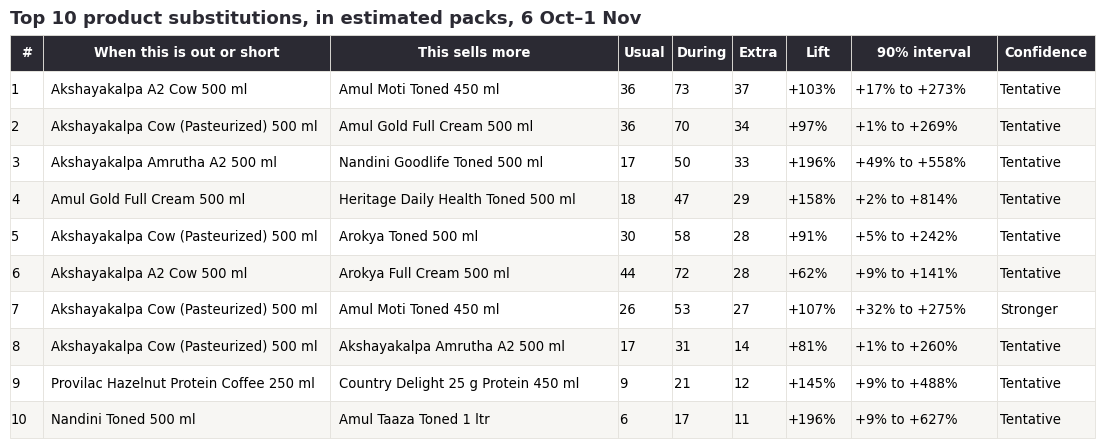

In [26]:
def table_png(frame, title, name, widths):
    fig, ax = plt.subplots(figsize=(14, .44 * (len(frame) + 1) + .4)); ax.axis("off")
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK, pad=8)
    tb = ax.table(cellText=frame.values, colLabels=frame.columns, colWidths=widths, bbox=[0, 0, 1, 1], cellLoc="left")
    tb.auto_set_font_size(False); tb.set_fontsize(9.5)
    for (r_, c_), cell in tb.get_celld().items():
        cell.set_edgecolor("#E4E2DC"); cell.set_linewidth(.6); cell.PAD = .03
        if r_ == 0:
            cell.set_facecolor(INK); cell.set_text_props(color="white", fontweight="bold")
        else:
            cell.set_facecolor("#FFFFFF" if r_ % 2 else "#F7F6F3")
    plt.savefig(f"{ROOT}charts/{name}.png", dpi=170, bbox_inches="tight"); plt.show()

def present(f, first, second):
    return pd.DataFrame({"#": range(1, len(f) + 1), "When this is out or short": f[first].values, "This sells more": f[second].values,
                         "Usual": f.Expected.round(0).astype(int).values, "During": f.Observed.round(0).astype(int).values,
                         "Extra": f["Extra packs"].round(0).astype(int).values, "Lift": [f"+{v:.0f}%" for v in f["Lift %"]],
                         "90% interval": [f"+{a:.0f}% to +{b:.0f}%" for a, b in zip(f["Low %"], f["High %"])],
                         "Confidence": ["Stronger" if v <= .25 else "Tentative" for v in f["q (FDR)"]]})

WIDTHS = [.03, .265, .265, .05, .055, .05, .06, .135, .09]
solid = lambda f, in_col, out_col: (f["Low %"] > 0) & (f[in_col] >= 5) & (f["Night share"] <= .6) \
    & (f["Normal half-hours"] >= (f["Normal half-hours"] + f[out_col]) / 3) & (f["Extra packs"] <= f["Packs A likely missed"])

good_p = prod_all[solid(prod_all, "Days out", "Out half-hours") & prod_all["Same need"]].sort_values("Extra packs", ascending=False)
top_products = good_p.head(10)
print(f"Products: {len(good_p)} of {tested_p.sum():,} tested pairs pass every test. Showing the top {len(top_products)}.")
table_png(present(top_products, "Out of stock", "Product that may gain"), f"Top {len(top_products)} product substitutions, in estimated packs, 6 Oct–1 Nov", "top10_product_substitutions", WIDTHS)

Brands: 7 of 193 tested pairs pass every test. Showing the top 7.


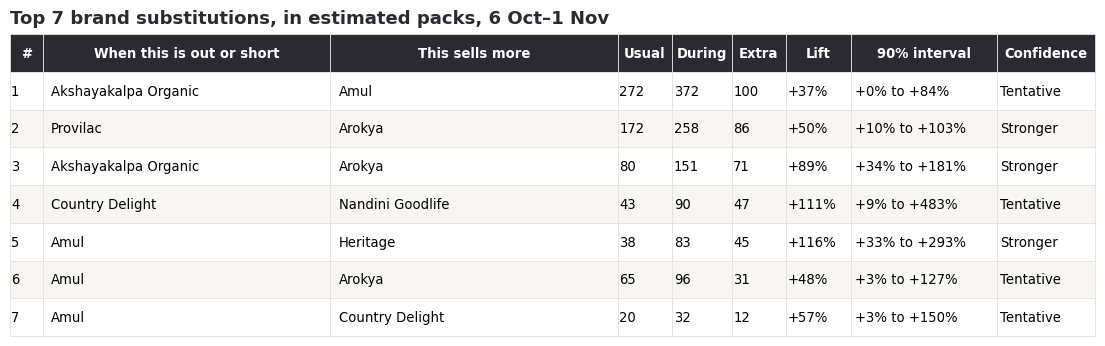

In [27]:
good_b = brand_all[solid(brand_all, "Days short", "Short half-hours")].sort_values("Extra packs", ascending=False)
top_brands = good_b.head(10)
print(f"Brands: {len(good_b)} of {tested.sum()} tested pairs pass every test. Showing the top {len(top_brands)}.")
table_png(present(top_brands, "Short brand", "Brand that may gain"), f"Top {len(top_brands)} brand substitutions, in estimated packs, 6 Oct–1 Nov", "top_brand_substitutions", WIDTHS)

## What this can't tell you

- **Sales are inferred from stock counts.** Decreases may include write-offs or corrections beyond those filtered.
- **Stock pinned at 12 after the morning reset** probably hides some morning sales of best sellers, so totals are conservative.
- **Store B was often hidden from 9 October.** Its sales while hidden are unknown, which affects trends and Provilac's share.
- **One address, one category, one month.** The stores also serve other areas.
- **Substitution results are associations.** Stockouts aren't random: they cluster at busy times and at the same store, so shared timing can look like switching. The bootstrap interval doesn't remove this, and with this many pairs, some flagged results will be chance. Results with a high FDR q-value should be treated as leads to test, not findings.
- **Listed prices only.** Discounts, coupons and fees aren't captured.